# Statistiques de pets

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/pets/pets_stats.ipynb)

Présentation et analyse statistique du jeu, lues du point de vue de Tiny-YOLO et de la
cible embarquée (entrée 416, grilles 13×13 et 26×26, 256 emplacements de `yolo_post`,
INT8). Tâches : [T32.6](../../docs/tasks/M32-trashnet-pets.md), [T32.10](../../docs/tasks/M32-trashnet-pets.md), [T16.4](../../docs/tasks/M16-presentation-jeux.md) ; jalon : [M16](../../docs/tasks/M16-presentation-jeux.md) ;
synthèse : [stats-jeux.md](../../docs/tasks/stats-jeux.md). Autres notebooks du jeu :
[tiny-yolov2-voc_infer](tiny-yolov2-voc_infer.ipynb), [tiny-yolov3-coco_infer](tiny-yolov3-coco_infer.ipynb), [tiny-yolov4-coco_infer](tiny-yolov4-coco_infer.ipynb), [tiny-yolov7-coco_infer](tiny-yolov7-coco_infer.ipynb), [tiny-yolov3-pets_infer](tiny-yolov3-pets_infer.ipynb), [tiny-yolov3-pets_train](tiny-yolov3-pets_train.ipynb), [tiny-yolov3-pets_sweep](tiny-yolov3-pets_sweep.ipynb), [tiny-yolov4-pets_infer](tiny-yolov4-pets_infer.ipynb), [tiny-yolov4-pets_train](tiny-yolov4-pets_train.ipynb), [tiny-yolov4-pets_sweep](tiny-yolov4-pets_sweep.ipynb).

Palier : annotations **R** (split entier), pixels **M** (`SAMPLE = 200`
images par partie). Prérequis : données `data/pets/annotations_val.json` — tools/get_datasets.sh pets. Ni poids ni GPU.

Question propre : How much larger is the body box than the head box, and how many images hold more than one animal? (renvoi : T32.8).

| | |
|---|---|
| source | https://www.robots.ox.ac.uk/~vgg/data/pets/ |
| version | 2012; whole-body boxes from the hand-made trimaps (tools/prep_datasets.py pets) |
| licence | CC BY-SA 4.0 (annotations); image copyright with the owners |
| capteur | pet photos from the web (Flickr and others), varied scenes |
| résolution typique | varies, most about 500×375 |
| officiel `train` | — images, — objets |
| officiel `val` | — images, — objets |
| officiel `test` | — images, — objets |
| chargeur | test = official test.txt; train / val = trainval.txt split 90 / 10 by breed |
| chargeur | an occluder (coat, hand, collar) often splits the mask: the box spans all the parts; the rare photos with two animals get one box over both |
| chargeur | masks under 2 % of the image or a head box outside the body box left out (`data/pets/rejected.json`) |
| chargeur | breeds map to VOC / COCO `cat` and `dog` (out-of-domain baseline) |

Aucun calcul ici : `tools/data_stats.py` calcule (`stats.json`, `stats.md`, galerie),
`tools/figures/donnees.py` trace ; chaque étape affiche la commande. Sorties dans
`build/notebooks/pets/stats/`, jamais dans `results/`. Notebook généré par `python -m tools.notebooks`
(`make notebooks`) : modifier `tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
DATASET   = 'pets'  # clé de DATASETS
SPLITS    = None  # liste de splits ; None : splits train puis test du jeu
SIZE      = None  # S ou 'LxH' ; None : entrée de la cfg du jeu (416 sinon)
RESIZE    = 'letterbox'  # letterbox | stretch (grandeurs vues par le réseau)
SAMPLE    = 200  # images lues pour les pixels, par partie ; 0 : aucune
GALLERY   = 8  # images de la galerie par split
SEED      = 0  # tirage des images (pixels, galerie, nuages)
NET       = 'build/m11/cfg/tiny-yolov3-pets.cfg'  # cfg dont les ancres et grilles servent aux collisions
DEVICE    = 'cpu'  # noyau CPU : rien ne tourne sur GPU
DATA_ROOT = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar ; None : pas de Drive
OUT       = 'build/notebooks/pets/stats'  # sorties du notebook
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV       = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
if str(NET).endswith(".cfg") and not env.restore_cfg(NET):
    print(f"cfg {NET} absente (tools/m11.sh {DATASET}-prep) : ancres et grilles de "
          "tiny-yolov3-coco pour les collisions")
    NET = "tiny-yolov3-coco"
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt /home/leonard/Documents/Perso/EmbeddedComputervision @ 145dc7c (modifié) ; Python 3.12.3 ; NumPy 2.4.2 ; backend cpu
données pets : data/pets/annotations_val.json ; poids : —


## Calcul (T16.0)

`tools/data_stats.py` lit les annotations de chaque split (en entier), lit les pixels
de `SAMPLE` images par partie (tirées avec `SEED`), dessine la galerie et trace les
figures. Les grandeurs « vues par le réseau » sont calculées après `RESIZE` à `SIZE`.

In [3]:
import json

from IPython.display import Image as Img, Markdown, display

from tools import data_stats as DS
from tools.notebooks.matrice import SPLIT_IMAGES, palier_stats
from yolo.models.tiny_yolo import load_cfg

if SIZE is None:
    _, h, w = load_cfg(NET)["input"]
    SIZE = h if h == w else f"{w}x{h}"
ann, px = palier_stats(DATASET, SAMPLE)
print(f"palier : annotations {ann}, pixels {px} ({SAMPLE} images par partie) ; "
      f"entrée {SIZE} ({RESIZE}) ; cfg {NET}")
C.run(C.cmd_data_stats(DATASET, OUT, SPLITS, SIZE, RESIZE, NET, SAMPLE, GALLERY, SEED,
                       data_root=DATA_ROOT))
STATS = json.loads(Path(OUT, "stats.json").read_text())
FIG = Path(OUT, "figures")


def show(name):
    png = FIG / f"{name}.png"
    if png.exists():
        display(Img(filename=str(png)))


def table(fn):
    text = fn(STATS)
    if text:
        display(Markdown(text))

palier : annotations R, pixels M (200 images par partie) ; entrée 416 (letterbox) ; cfg build/m11/cfg/tiny-yolov3-pets.cfg
$ python tools/data_stats.py --dataset pets --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-pets.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/pets/stats


chargement pets train…


chargement pets test…


analyses train (3302 images)…


analyses test (3662 images)…


...

→ build/notebooks/pets/stats/figures/intensites.png


→ build/notebooks/pets/stats/figures/ancres.png


→ build/notebooks/pets/stats/figures/ancres_k.png


→ build/notebooks/pets/stats/figures/ecart.png


  (25 s)


## Présentation et galerie (T16.4)

Classes du jeu et leur correspondance VOC et COCO (`MAPPINGS`), puis `GALLERY` images
par split, une image par classe ; vérités terrain dessinées par `tools/detect.py:draw`.
À `SEED` fixé, la galerie ne change pas.

| classe | VOC | COCO |
|---|---|---|
| Abyssinian | cat | cat |
| american_bulldog | dog | dog |
| american_pit_bull_terrier | dog | dog |
| basset_hound | dog | dog |
| beagle | dog | dog |
| Bengal | cat | cat |
| Birman | cat | cat |
| Bombay | cat | cat |
| boxer | dog | dog |
| British_Shorthair | cat | cat |
| chihuahua | dog | dog |
| Egyptian_Mau | cat | cat |
| english_cocker_spaniel | dog | dog |
| english_setter | dog | dog |
| german_shorthaired | dog | dog |
| great_pyrenees | dog | dog |
| havanese | dog | dog |
| japanese_chin | dog | dog |
| keeshond | dog | dog |
| leonberger | dog | dog |
| Maine_Coon | cat | cat |
| miniature_pinscher | dog | dog |
| newfoundland | dog | dog |
| Persian | cat | cat |
| pomeranian | dog | dog |
| pug | dog | dog |
| Ragdoll | cat | cat |
| Russian_Blue | cat | cat |
| saint_bernard | dog | dog |
| samoyed | dog | dog |
| scottish_terrier | dog | dog |
| shiba_inu | dog | dog |
| Siamese | cat | cat |
| Sphynx | cat | cat |
| staffordshire_bull_terrier | dog | dog |
| wheaten_terrier | dog | dog |
| yorkshire_terrier | dog | dog |

galerie : train


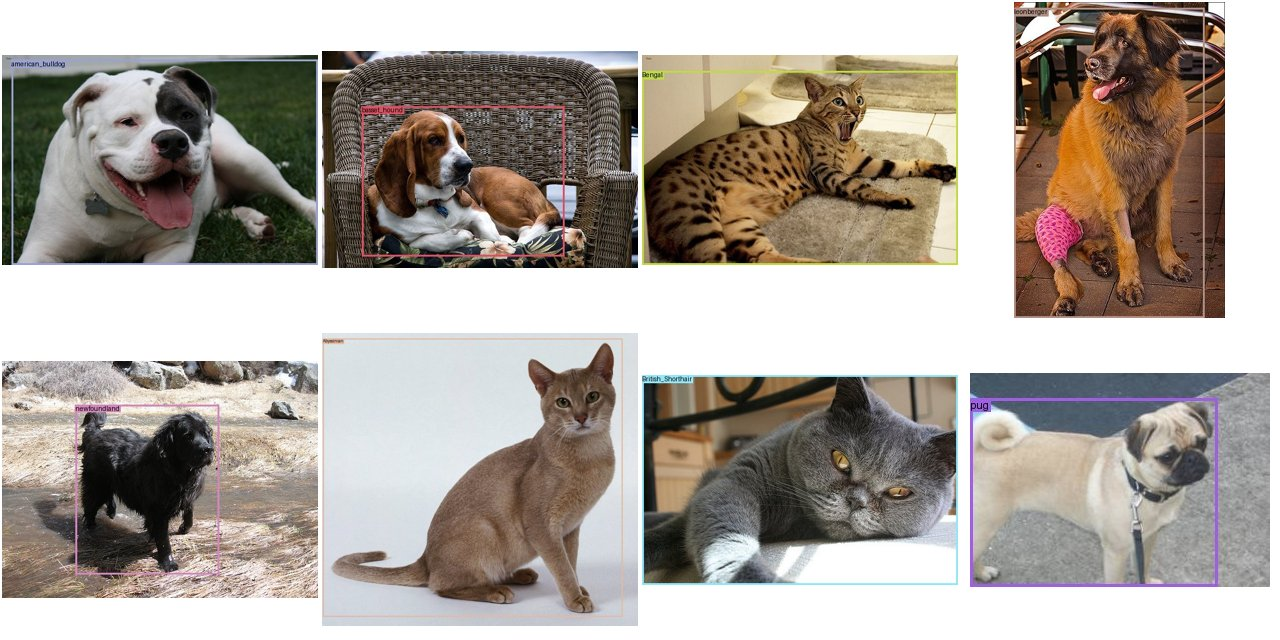

galerie : test


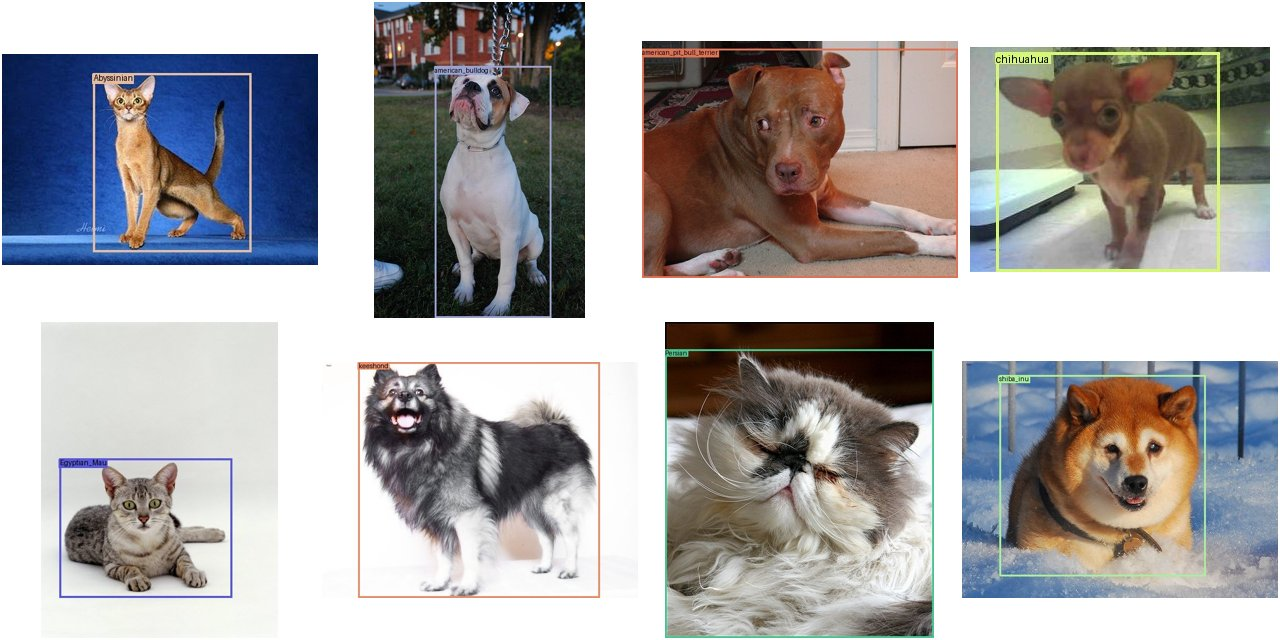

galerie : classes


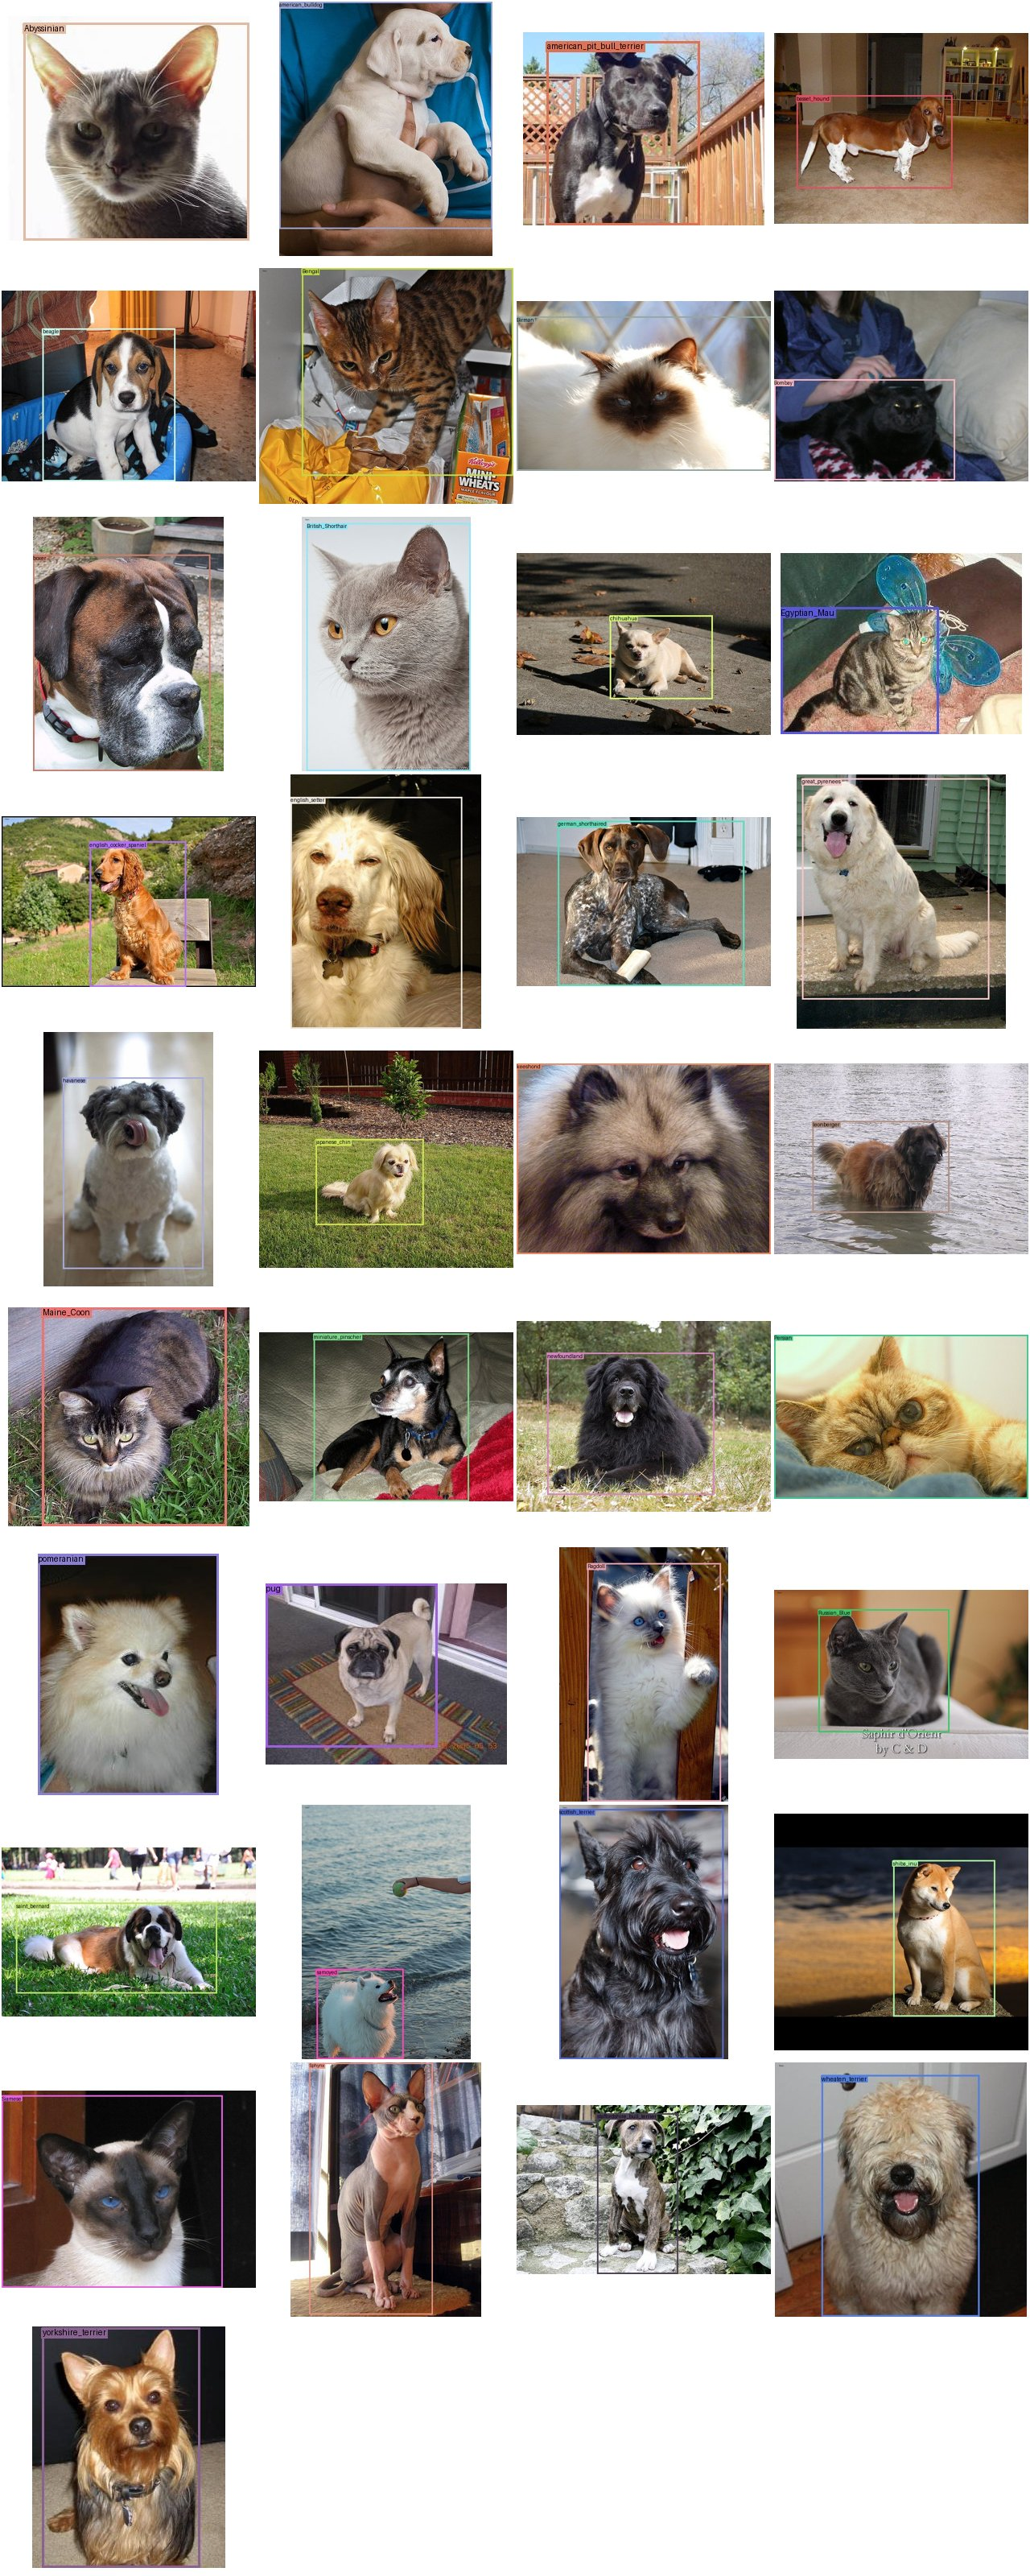

In [4]:
from yolo.data import datasets as D

rows = ["| classe | VOC | COCO |", "|---|---|---|"]
for c in D.DATASETS[DATASET].classes:
    m = [c if DATASET == f else D.MAPPINGS.get((DATASET, f), {}).get(c, "—")
         for f in ("voc", "coco")]
    rows.append(f"| {c} | {m[0]} | {m[1]} |")
display(Markdown("\n".join(rows)))
for g, sheet in STATS.get("galerie", {}).get("planches", {}).items():
    if g != "suspectes":
        print(f"galerie : {g}")
        display(Img(filename=str(Path(OUT, sheet))))

## Comptes et classes (T16.5)

Comptes par split (annotations, split entier), face aux effectifs officiels de la
fiche ; objets par classe et co-occurrence.

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 3 302 | 3 302 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| test | 3 662 | 3 662 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| ensemble | 6 964 | 6 964 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |

train : 3302 images, 3302 objets ; officiel — / — : ok
test : 3662 images, 3662 objets ; officiel — / — : ok


| classe | train : objets (images) | test : objets (images) | côté médian (px, letterbox) | petits |
|---|---|---|---|---|
| Abyssinian | 90 (90) | 98 (98) | 298 | 0 % |
| american_bulldog | 90 (90) | 100 (100) | 279 | 0 % |
| american_pit_bull_terrier | 90 (90) | 100 (100) | 293 | 0 % |
| basset_hound | 89 (89) | 100 (100) | 266 | 0 % |
| beagle | 90 (90) | 100 (100) | 257 | 0 % |
| Bengal | 90 (90) | 100 (100) | 291 | 0 % |
| Birman | 90 (90) | 100 (100) | 295 | 0 % |
| Bombay | 86 (86) | 88 (88) | 308 | 0 % |
| boxer | 90 (90) | 99 (99) | 280 | 0 % |
| British_Shorthair | 90 (90) | 100 (100) | 296 | 0 % |
| chihuahua | 90 (90) | 100 (100) | 285 | 0 % |
| Egyptian_Mau | 81 (81) | 96 (96) | 300 | 0 % |
| english_cocker_spaniel | 86 (86) | 100 (100) | 277 | 0 % |
| english_setter | 90 (90) | 100 (100) | 283 | 0 % |
| german_shorthaired | 90 (90) | 100 (100) | 259 | 0 % |
| great_pyrenees | 90 (90) | 100 (100) | 282 | 0 % |
| havanese | 90 (90) | 100 (100) | 292 | 0 % |
| japanese_chin | 90 (90) | 99 (99) | 289 | 0 % |
| keeshond | 90 (90) | 98 (98) | 294 | 0 % |
| leonberger | 89 (89) | 100 (100) | 290 | 0 % |
| Maine_Coon | 90 (90) | 100 (100) | 305 | 0 % |
| miniature_pinscher | 89 (89) | 100 (100) | 273 | 0 % |
| newfoundland | 86 (86) | 100 (100) | 281 | 0 % |
| Persian | 90 (90) | 99 (99) | 320 | 0 % |
| pomeranian | 90 (90) | 100 (100) | 299 | 0 % |
| pug | 90 (90) | 100 (100) | 290 | 0 % |
| Ragdoll | 90 (90) | 100 (100) | 311 | 0 % |
| Russian_Blue | 90 (90) | 100 (100) | 291 | 0 % |
| saint_bernard | 87 (87) | 98 (98) | 281 | 0 % |
| samoyed | 90 (90) | 100 (100) | 269 | 0 % |
| scottish_terrier | 90 (90) | 99 (99) | 279 | 0 % |
| shiba_inu | 90 (90) | 100 (100) | 257 | 0 % |
| Siamese | 89 (89) | 100 (100) | 296 | 0 % |
| Sphynx | 90 (90) | 100 (100) | 290 | 0 % |
| staffordshire_bull_terrier | 90 (90) | 89 (89) | 280 | 0 % |
| wheaten_terrier | 90 (90) | 99 (99) | 258 | 0 % |
| yorkshire_terrier | 90 (90) | 100 (100) | 284 | 0 % |

Rapport classe la plus / la moins fréquente : 1.

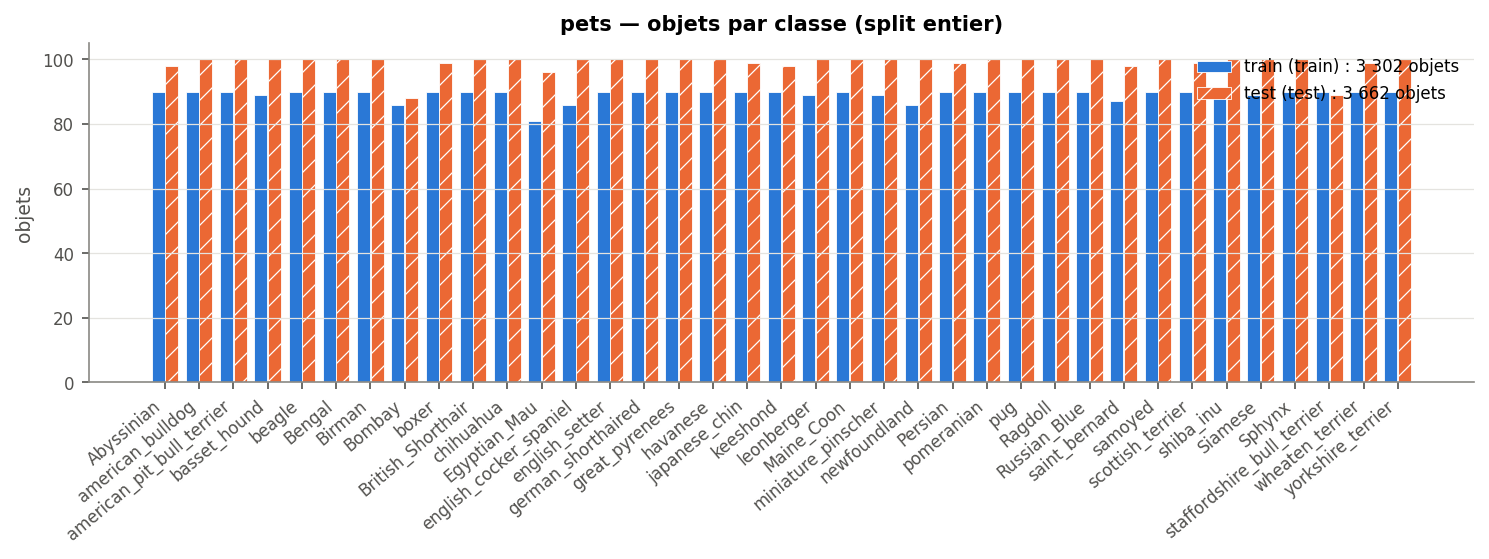

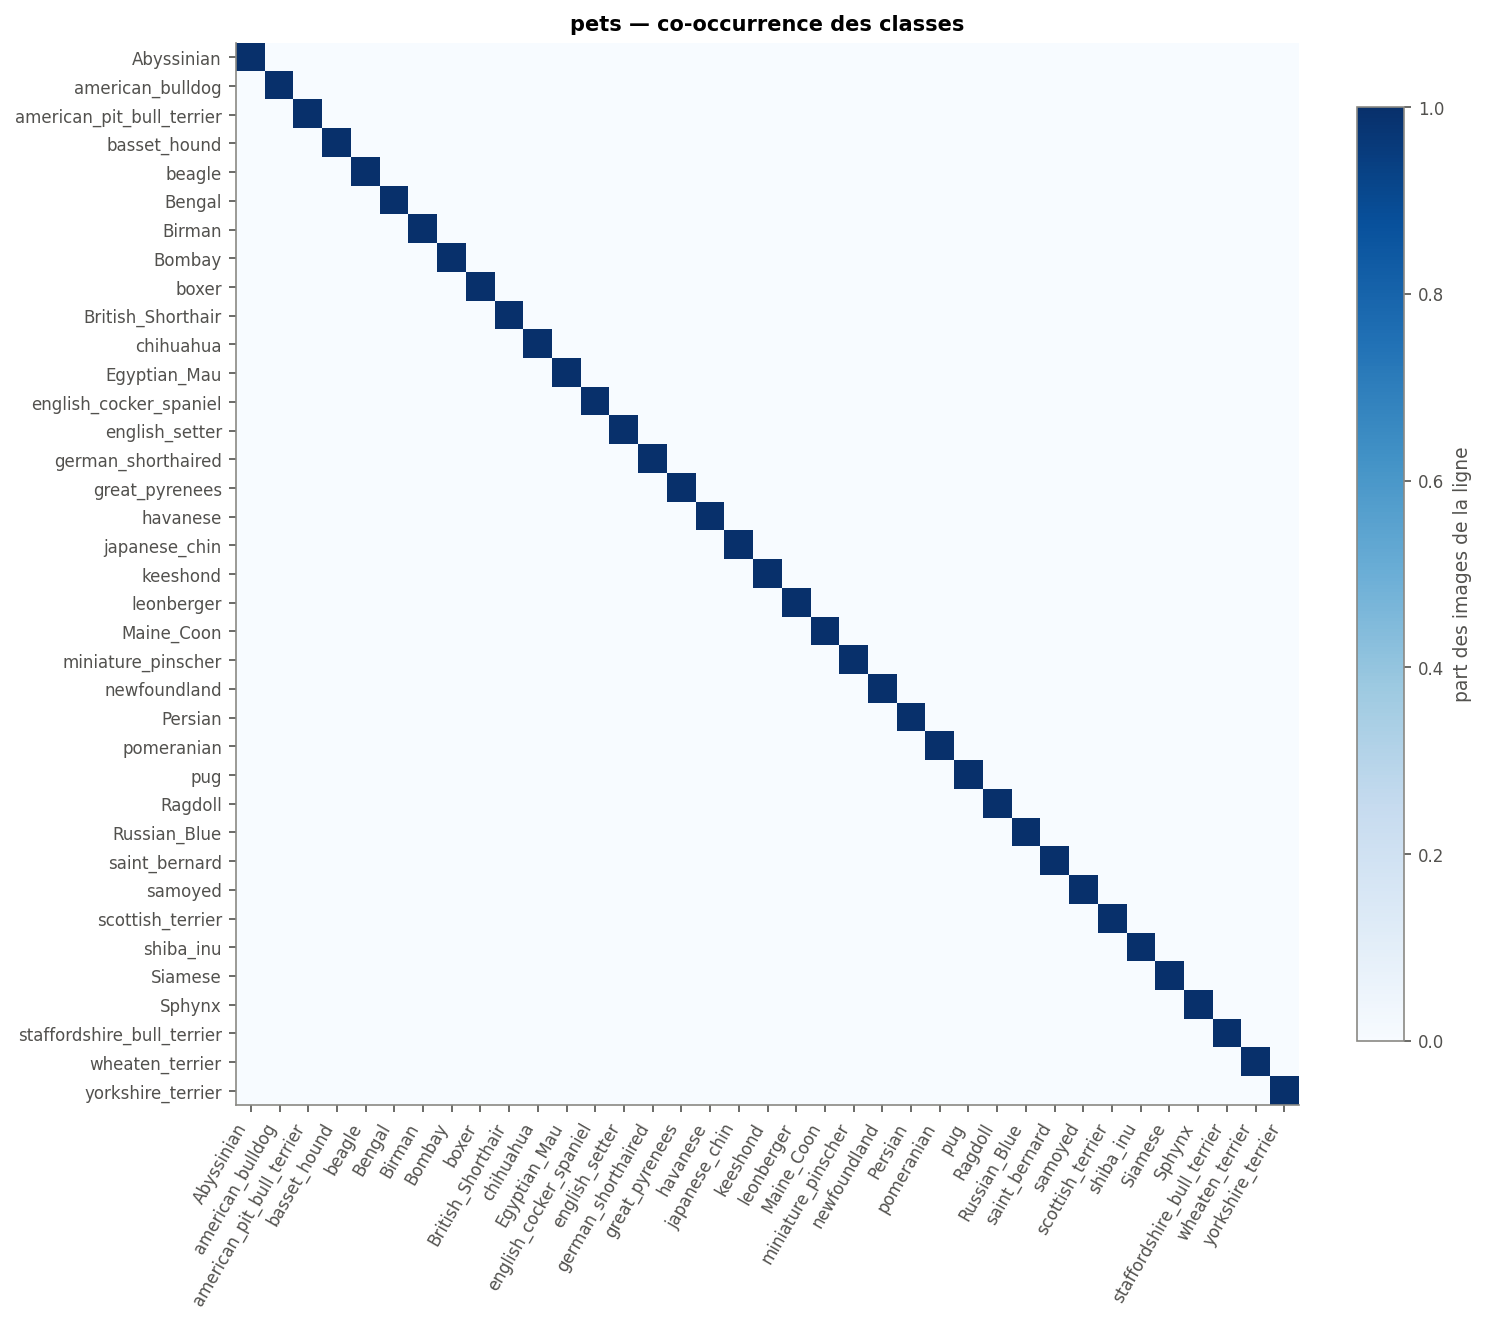

In [5]:
table(DS.md_synthese)
chk = DS.check_official(STATS)
for sp, i, o, (a, b), ok in chk:
    print(f"{sp} : {i} images, {o} objets ; officiel {a or '—'} / {b or '—'} : "
          f"{'ok' if ok else 'écart (voir les notes de la fiche)'}")
table(DS.md_classes)
show("classes")
show("cooccurrence")

## Géométrie des boîtes (T16.6)

Tailles en pixels d'origine et d'entrée (letterbox et stretch à `SIZE`), catégories
COCO avant et après redimensionnement, part des objets plus petits qu'une cellule de
chaque tête, centres des boîtes.

| repère | petits | moyens | grands | côté médian (px) | plus petits qu'une cellule | hauteur < 8 px |
|---|---|---|---|---|---|---|
| image d'origine | 0,0 % | 0,1 % | 99,9 % | 326 | — | — |
| letterbox 416×416 | 0,0 % | 0,2 % | 99,8 % | 287 | 13x13 0,0 % · 26x26 0,0 % | 0,0 % |
| stretch 416×416 | 0,0 % | 0,1 % | 99,9 % | 339 | 13x13 0,0 % · 26x26 0,0 % | 0,0 % |

6 964 objets non-difficult ; pas des têtes : 13x13 → 32 px, 26x26 → 16 px.

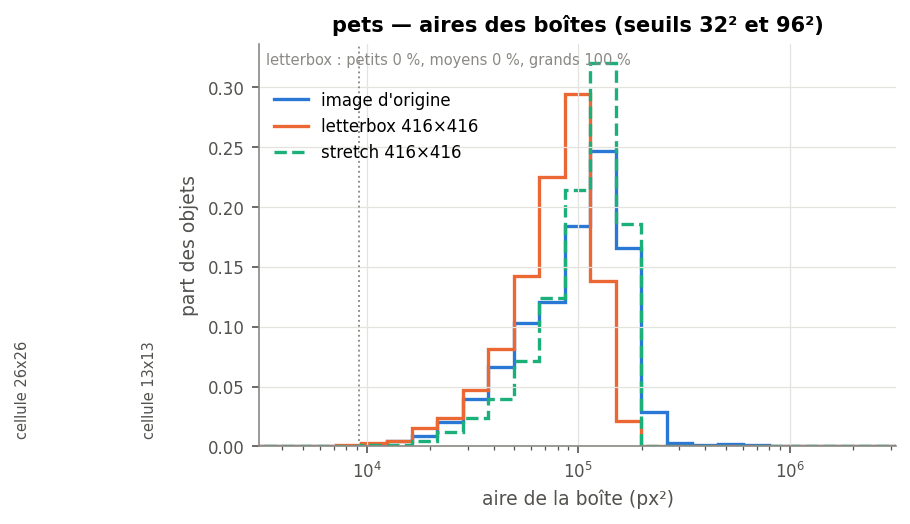

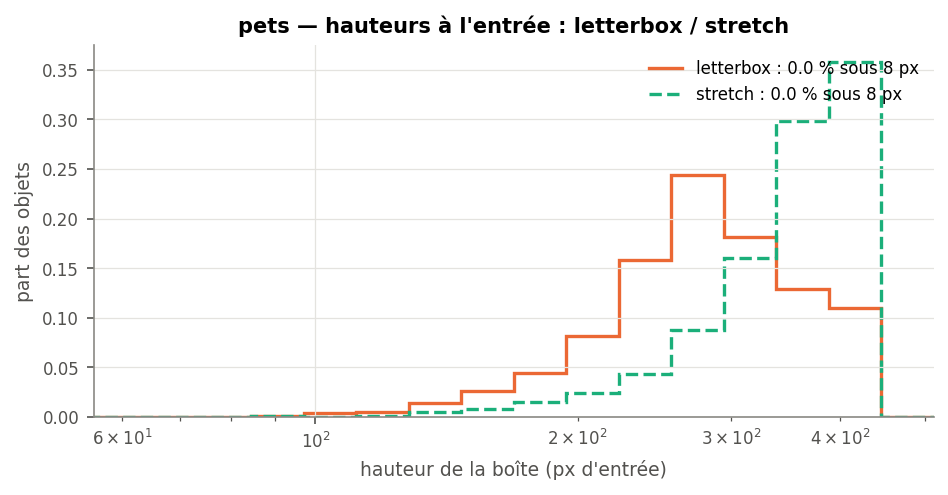

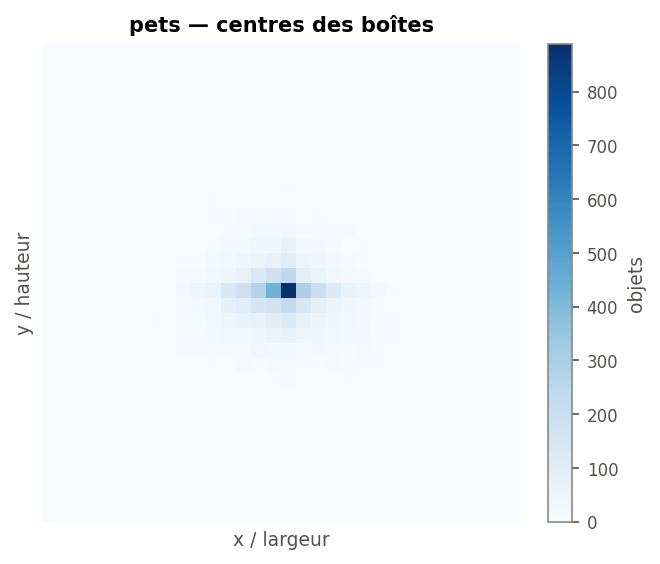

In [6]:
table(DS.md_geometrie)
show("tailles")
show("letterbox_stretch")
show("centres")

## Densité et collisions (T16.7)

Objets par image face aux 256 emplacements de `yolo_post` ; cibles perdues quand deux
objets tombent sur la même cellule et la même ancre (`build_targets`, ancres de `NET`).

| partie | objets/image moy. | méd. | max | > 256 / > 1 024 | cibles perdues | par tête (perdues / objets) | images touchées |
|---|---|---|---|---|---|---|---|
| train | 1,0 | 1 | 1 | 0 / 0 | 0 / 3 302 (0,00 %) | 13x13 : 0 / 1 835 · 26x26 : 0 / 1 467 | 0 |
| test | 1,0 | 1 | 1 | 0 / 0 | 0 / 3 662 (0,00 %) | 13x13 : 0 / 1 956 · 26x26 : 0 / 1 706 | 0 |
| ensemble | 1,0 | 1 | 1 | 0 / 0 | 0 / 6 964 (0,00 %) | 13x13 : 0 / 3 791 · 26x26 : 0 / 3 173 | 0 |

Ancres de `build/m11/cfg/tiny-yolov3-pets.cfg` ; objets non-difficult, comme à l'entraînement.

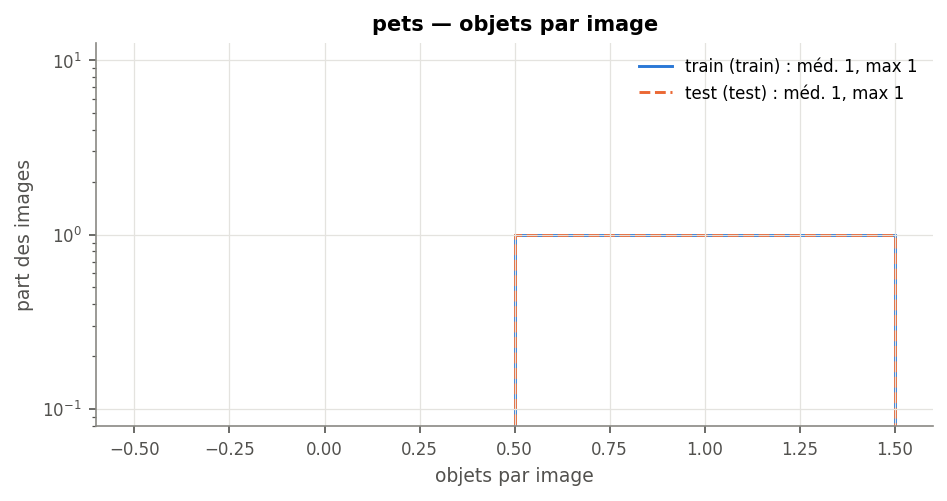

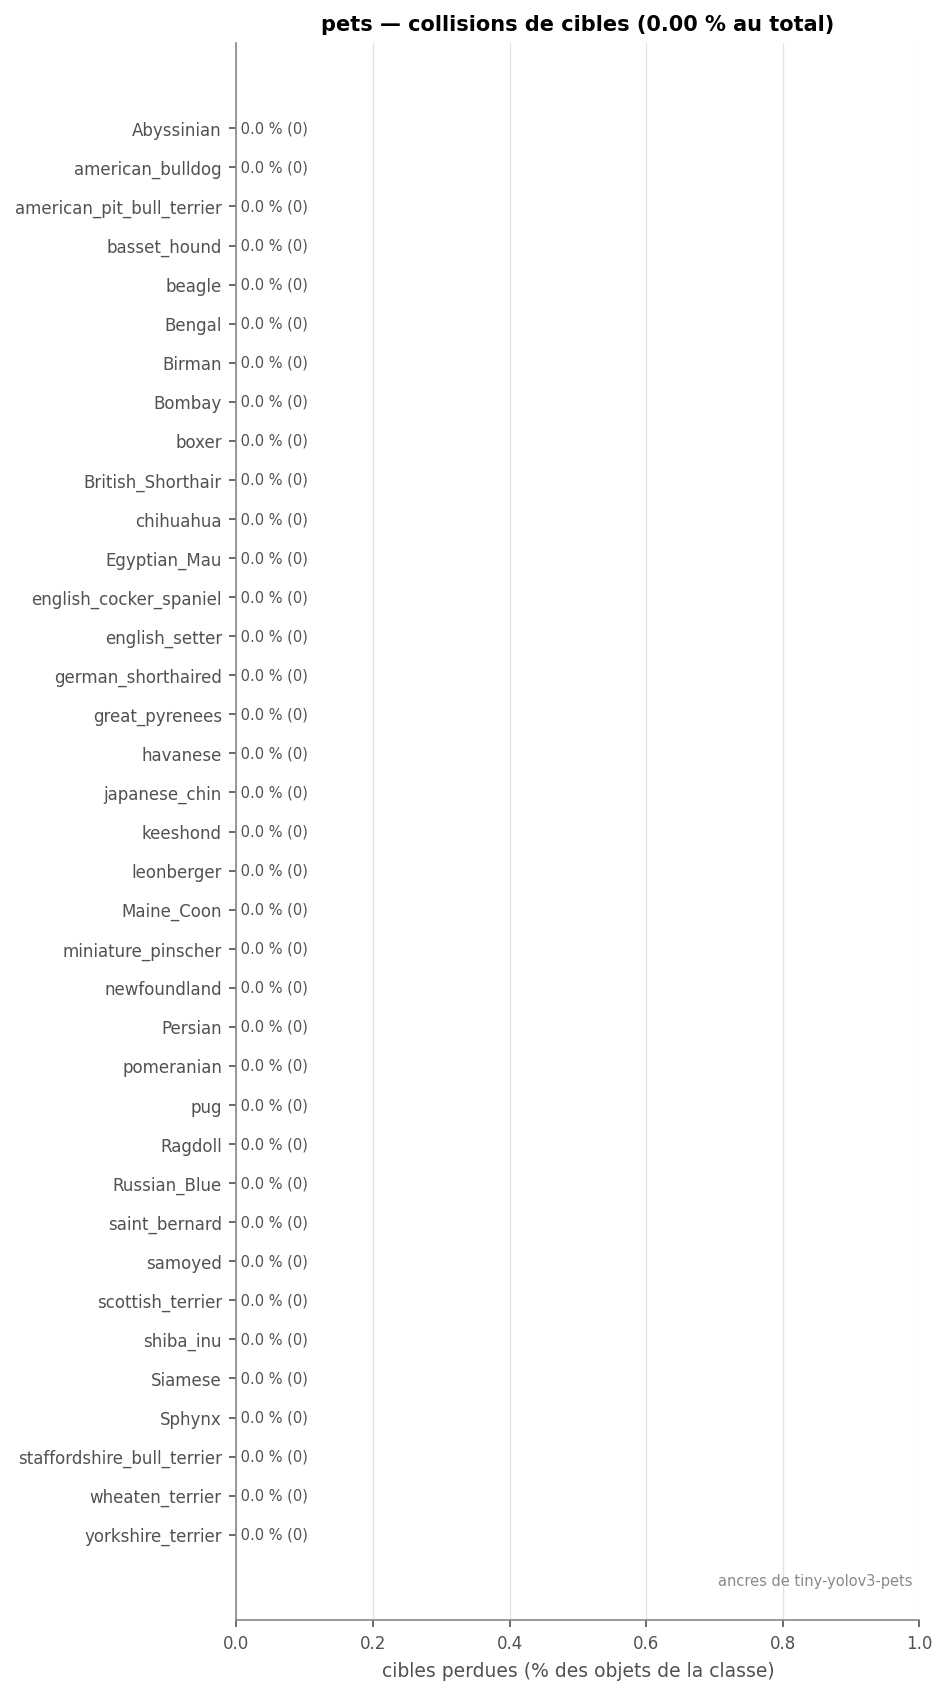

In [7]:
table(DS.md_densite)
show("densite")
show("collisions")

## Images (T16.8)

Résolutions sur le split entier (annotations) ; canaux, intensités et luminance sur
`SAMPLE` images par partie, face à VOC2007 test (échelles INT8 de M4).

| partie | résolutions (3 premières) | distinctes | pixels sur | canaux | moyenne par canal | écart type par canal | luminance moy. | niveaux 8 bits → INT8 |
|---|---|---|---|---|---|---|---|---|
| train | 500×375 (688), 500×333 (437), 375×500 (222) | 663 | 200 images | 3 | 116,5 / 107,4 / 95,7 | 70,6 / 69,3 / 69,3 | 114,1 | 256 → 128 |
| test | 500×375 (652), 500×333 (581), 333×500 (287) | 649 | 200 images | 3 | 125,9 / 117,9 / 102,0 | 68,4 / 68,5 / 70,3 | 118,2 | 256 → 128 |
| ensemble | 500×375 (1 340), 500×333 (1 018), 333×500 (484) | 986 | 200 images | 3 | 117,1 / 106,9 / 94,6 | 68,1 / 66,9 / 67,3 | 114,2 | 256 → 128 |

Référence VOC2007 test (200 images, graine 0) : luminance moyenne 107,7, moyenne par canal 112,1 / 107,1 / 98,5.

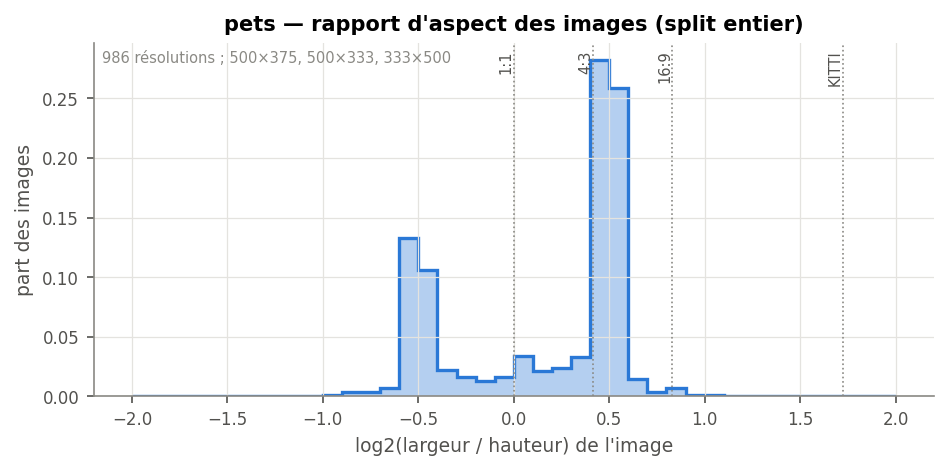

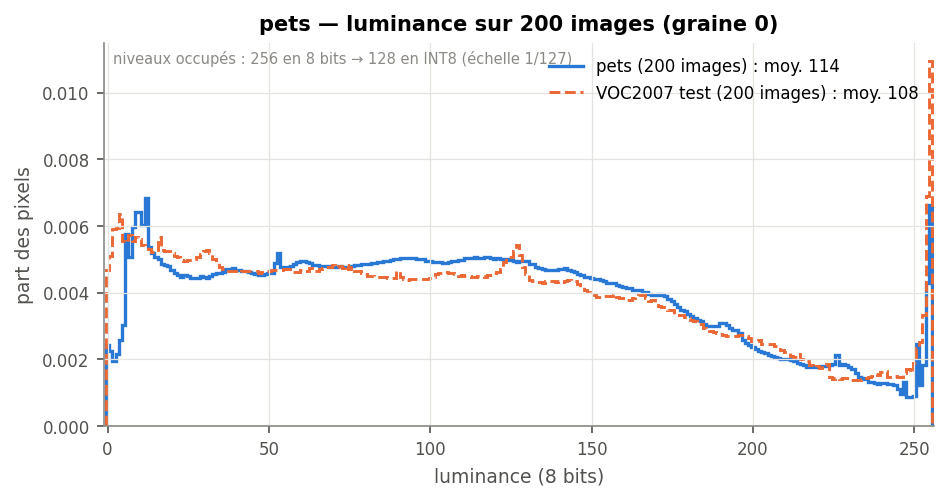

In [8]:
table(DS.md_images)
show("resolutions")
show("intensites")

## Ancres (T16.9)

Boîtes du groupe train en pixels d'entrée letterbox, ancres de la cfg, de VOC, de
COCO et du k-means (`tools/kmeans_anchors.py`, mêmes `--size` et `--seed`).

| ancres | w,h (px à 416×416) | IoU moyenne |
|---|---|---|
| VOC (tiny-yolov2-voc) | `35,38  109,141  212,364  301,164  532,337` | 0,6623 |
| VOC (tiny-yolov3-voc) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,6832 |
| COCO (tiny-yolov3-coco) | `10,14  23,27  37,58  81,82  135,169  344,319` | 0,6832 |
| cfg du jeu (tiny-yolov3-pets) | `151,194  214,279  304,213  267,373  357,278  383,356` | 0,8235 |
| k-means k = 5 (graine 0) | `151,206  227,263  328,233  268,374  376,312` | 0,8138 |
| k-means k = 6 (graine 0) | `151,194  214,279  304,213  267,373  357,278  383,356` | 0,8235 |

3 302 boîtes non-difficult du groupe train, letterbox 416×416.

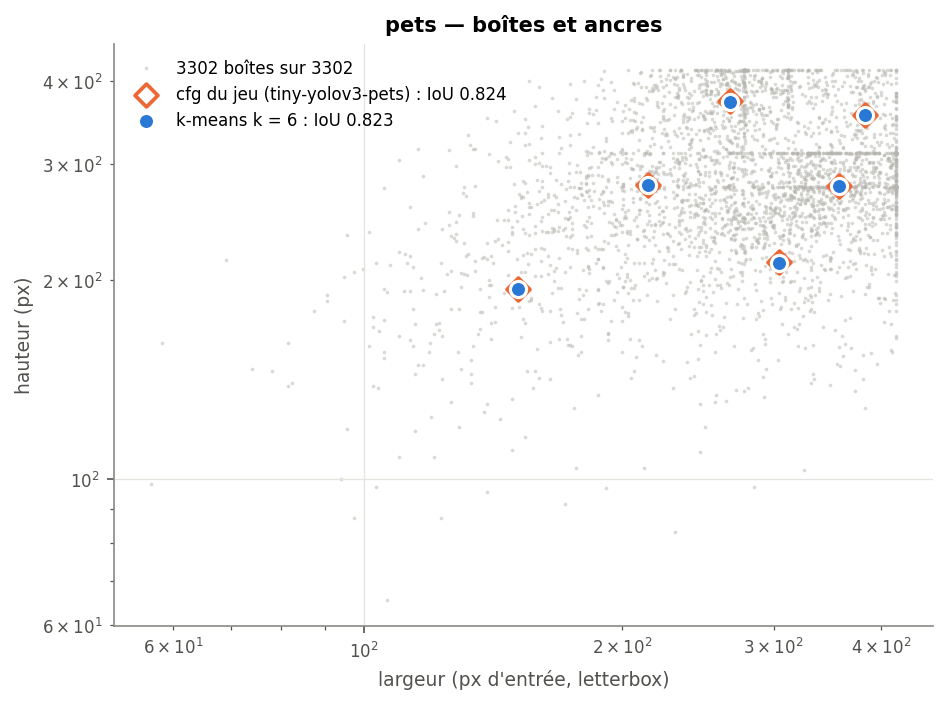

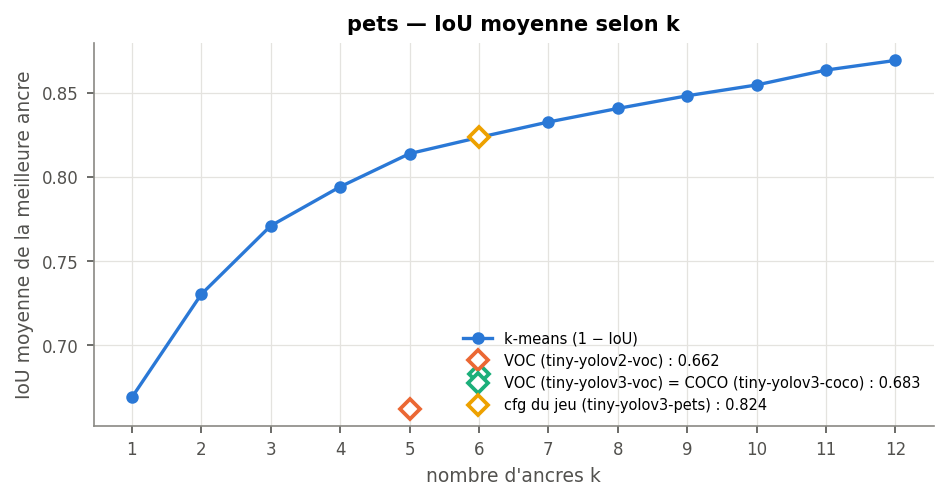

In [9]:
table(DS.md_ancres)
show("ancres")
show("ancres_k")

## Qualité des annotations (T16.10)

Boîtes retirées ou rognées par le chargeur, dégénérées, doublons, régions retirées ;
l'analyse signale, elle ne corrige pas (une correction passe par M11).

In [10]:
table(DS.md_qualite)
sus = DS.whole(STATS).get("qualite", {}).get("suspects", [])
for d in sus:
    print(f"{d['id']} : score {d['score']} (retirées {d['retirées']}, rognées "
          f"{d['rognées']}, dégénérées {d['dégénérées']}, doublons {d['doublons']})")
sheet = STATS.get("galerie", {}).get("planches", {}).get("suspectes")
if sheet:
    display(Img(filename=str(Path(OUT, sheet))))

| partie | retirées (make_sample) | rognées | côté < 2 px (orig. / entrée) | doublons (IoU > 0,95) | régions retirées par le chargeur |
|---|---|---|---|---|---|
| train | — | 0 | 0 / 0 | 0 | — |
| test | — | 0 | 0 / 0 | 0 | — |
| ensemble | — | 0 | 0 / 0 | 0 | — |

## Écart entre splits et couverture hors domaine (T16.11)

Distance en variation totale entre train et test, par grandeur ; part des objets qui
ont une classe VOC ou COCO (ce qu'évaluent les notebooks hors domaine de T14.5).

| grandeur (train ↔ test) | variation totale |
|---|---|
| classes | 0,007 |
| area_in | 0,037 |
| w_in | 0,054 |
| h_in | 0,031 |
| aspect | 0,043 |
| per_image | 0,000 |

| split | classes du modèle | objets couverts | part | évalués (non-difficult) |
|---|---|---|---|---|
| train | VOC | 3 302 | 100,0 % | 3 302 |
| train | COCO | 3 302 | 100,0 % | 3 302 |
| test | VOC | 3 662 | 100,0 % | 3 662 |
| test | COCO | 3 662 | 100,0 % | 3 662 |

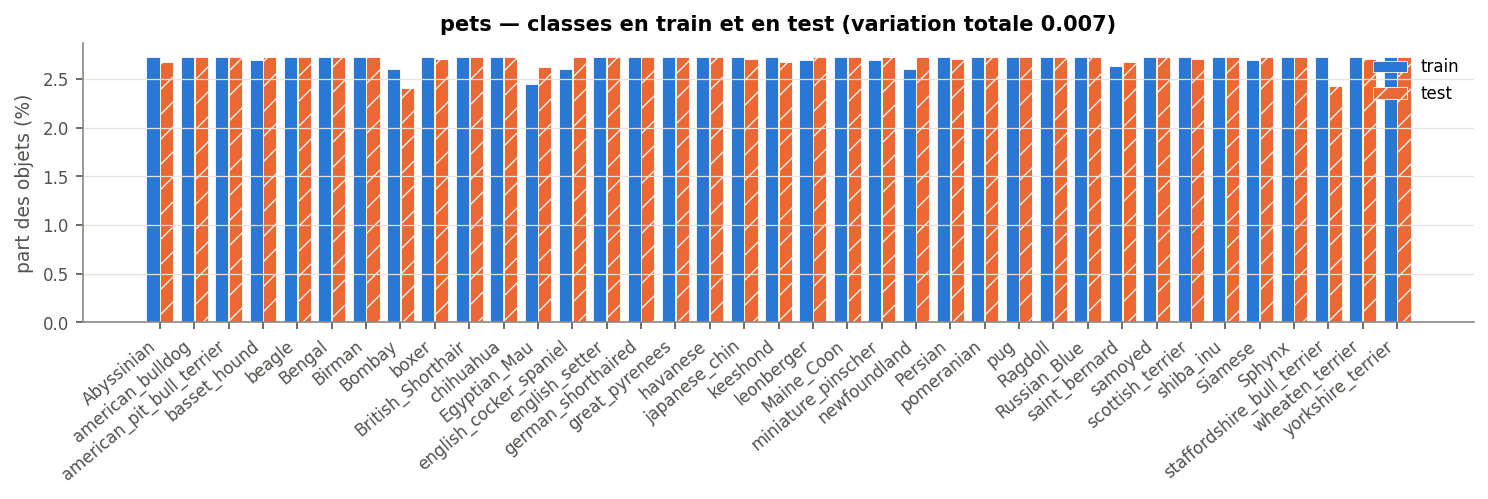

In [11]:
table(DS.md_ecart)
show("ecart")

## Question propre au jeu

How much larger is the body box than the head box, and how many images hold more than one animal? (renvoi : T32.8)

In [12]:
import json
from pathlib import Path
import numpy as np
from yolo.data.datasets import DATA_DIR
root = Path(DATA_ROOT or DATA_DIR / "pets")
es = [e for s in ("train", "val", "test")
      for e in json.loads((root / f"annotations_{s}.json").read_text())]
area = lambda b: (b[2] - b[0]) * (b[3] - b[1])
r = np.array([area(e["boxes"][0]) / area(e["head"]) for e in es if e["head"]])
print(f"body / head box area, {len(r)} trainval images: median {np.median(r):.1f}, "
      f"q10 {np.quantile(r, 0.1):.1f}, q90 {np.quantile(r, 0.9):.1f}")
multi = sum(e["components"] > 1 for e in es)
print(f"mask in several parts over 1 % of the image: {multi} of {len(es)} images "
      f"({100 * multi / len(es):.1f} %); mostly one animal cut by a coat, a hand or a "
      "leash, a few with two animals (one box over both)")
display(Markdown(DS.md_par_classe(STATS)))

body / head box area, 3662 trainval images: median 3.7, q10 1.8, q90 9.3
mask in several parts over 1 % of the image: 131 of 7332 images (1.8 %); mostly one animal cut by a coat, a hand or a leash, a few with two animals (one box over both)


| classe | objets (test, non-difficult) | part | côté médian (px) | petits | cibles perdues |
|---|---|---|---|---|---|
| Abyssinian | 98 | 2,7 % | 304 | 0 % | 0,00 % |
| american_bulldog | 100 | 2,7 % | 280 | 0 % | 0,00 % |
| american_pit_bull_terrier | 100 | 2,7 % | 276 | 0 % | 0,00 % |
| basset_hound | 100 | 2,7 % | 273 | 0 % | 0,00 % |
| beagle | 100 | 2,7 % | 259 | 0 % | 0,00 % |
| Bengal | 100 | 2,7 % | 287 | 0 % | 0,00 % |
| Birman | 100 | 2,7 % | 305 | 0 % | 0,00 % |
| Bombay | 88 | 2,4 % | 307 | 0 % | 0,00 % |
| boxer | 99 | 2,7 % | 297 | 0 % | 0,00 % |
| British_Shorthair | 100 | 2,7 % | 301 | 0 % | 0,00 % |
| chihuahua | 100 | 2,7 % | 274 | 0 % | 0,00 % |
| Egyptian_Mau | 96 | 2,6 % | 296 | 0 % | 0,00 % |
| english_cocker_spaniel | 100 | 2,7 % | 280 | 0 % | 0,00 % |
| english_setter | 100 | 2,7 % | 277 | 0 % | 0,00 % |
| german_shorthaired | 100 | 2,7 % | 255 | 0 % | 0,00 % |
| great_pyrenees | 100 | 2,7 % | 281 | 0 % | 0,00 % |
| havanese | 100 | 2,7 % | 292 | 0 % | 0,00 % |
| japanese_chin | 99 | 2,7 % | 282 | 0 % | 0,00 % |
| keeshond | 98 | 2,7 % | 292 | 0 % | 0,00 % |
| leonberger | 100 | 2,7 % | 282 | 0 % | 0,00 % |
| Maine_Coon | 100 | 2,7 % | 306 | 0 % | 0,00 % |
| miniature_pinscher | 100 | 2,7 % | 253 | 0 % | 0,00 % |
| newfoundland | 100 | 2,7 % | 272 | 0 % | 0,00 % |
| Persian | 99 | 2,7 % | 317 | 0 % | 0,00 % |
| pomeranian | 100 | 2,7 % | 285 | 0 % | 0,00 % |
| pug | 100 | 2,7 % | 268 | 0 % | 0,00 % |
| Ragdoll | 100 | 2,7 % | 309 | 0 % | 0,00 % |
| Russian_Blue | 100 | 2,7 % | 294 | 0 % | 0,00 % |
| saint_bernard | 98 | 2,7 % | 266 | 0 % | 0,00 % |
| samoyed | 100 | 2,7 % | 275 | 0 % | 0,00 % |
| scottish_terrier | 99 | 2,7 % | 260 | 0 % | 0,00 % |
| shiba_inu | 100 | 2,7 % | 258 | 0 % | 0,00 % |
| Siamese | 100 | 2,7 % | 307 | 0 % | 0,00 % |
| Sphynx | 100 | 2,7 % | 299 | 0 % | 0,00 % |
| staffordshire_bull_terrier | 89 | 2,4 % | 260 | 0 % | 0,00 % |
| wheaten_terrier | 99 | 2,7 % | 257 | 0 % | 0,00 % |
| yorkshire_terrier | 100 | 2,7 % | 277 | 0 % | 0,00 % |

## Résumé

In [13]:
table(DS.md_synthese)
print(f"sorties : {OUT}/ (stats.json, stats.md, figures/, galerie/) ; "
      f"révision {TRACE['rev']}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

| partie | images | objets | difficult | images vides | objets/image (méd. / max) | petits < 32² à 416×416 | plus petits qu'une cellule | cibles perdues | images > 256 / > 1 024 |
|---|---|---|---|---|---|---|---|---|---|
| train | 3 302 | 3 302 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| test | 3 662 | 3 662 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |
| ensemble | 6 964 | 6 964 | 0 | 0 | 1 / 1 | 0,0 % | 13x13 0,0 % · 26x26 0,0 % | 0,00 % | 0 / 0 |

sorties : build/notebooks/pets/stats/ (stats.json, stats.md, figures/, galerie/) ; révision 145dc7c
commandes équivalentes :
  python tools/data_stats.py --dataset pets --size 416 --resize letterbox --net build/m11/cfg/tiny-yolov3-pets.cfg --sample 200 --gallery 8 --seed 0 --figures --out build/notebooks/pets/stats
